# Chapter 7: Customizing Every Part of a Chart

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 7.1 Ticks and Number Formats

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

plt.style.use('book.mplstyle')

In [2]:
sales = pd.read_csv('monthly_sales.csv')
sales.head(3)

,month,sales_2024,sales_2025
0,Jan,33100,38200
1,Feb,31800,35900
2,Mar,36900,42800


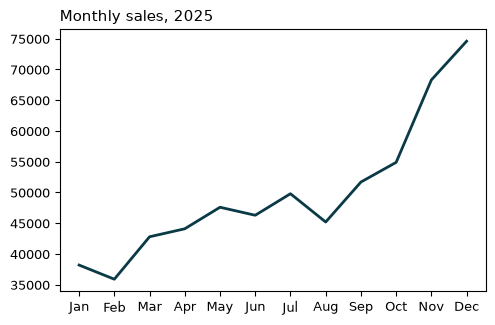

In [3]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
plt.show()

### `StrMethodFormatter`

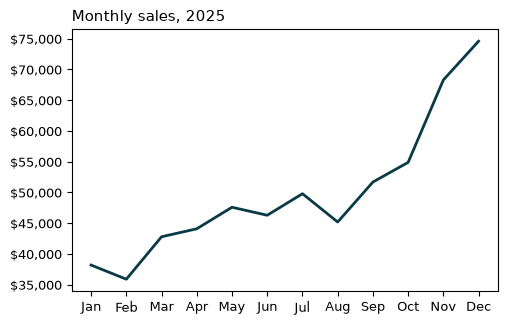

In [4]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.yaxis.set_major_formatter(StrMethodFormatter('${x:,.0f}'))
plt.show()

### `PercentFormatter`

In [5]:
funnel = pd.read_csv('monthly_funnel.csv')
funnel.head(3)

,month,visits,orders,conversion
0,January,21400,470,0.0220
1,February,20100,452,0.0225
2,March,23800,547,0.0230


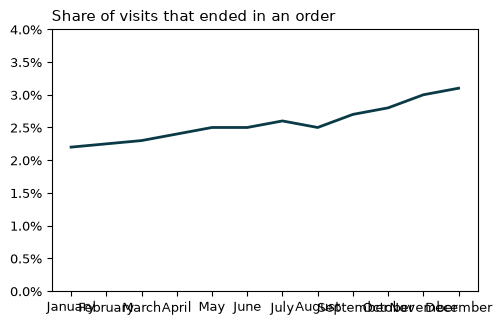

In [6]:
fig, ax = plt.subplots()
ax.plot(funnel['month'], funnel['conversion'])
ax.set_title('Share of visits that ended in an order')
ax.set_ylim(0, 0.04)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
plt.show()

### `ax.tick_params()`

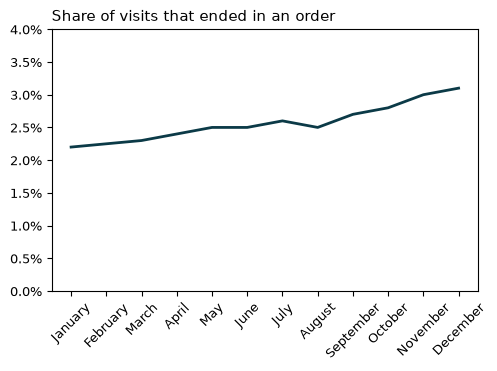

In [7]:
fig, ax = plt.subplots()
ax.plot(funnel['month'], funnel['conversion'])
ax.set_title('Share of visits that ended in an order')
ax.set_ylim(0, 0.04)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=1))
ax.tick_params(axis='x', labelrotation=45)
plt.show()

## 7.2 Log Scales, Spines and Grids

### `ax.set_xscale()`

In [8]:
pages = pd.read_csv('page_visits.csv')
pages.head(3)

,page,visits
0,Home,182000
1,Products,96400
2,Cart,21300


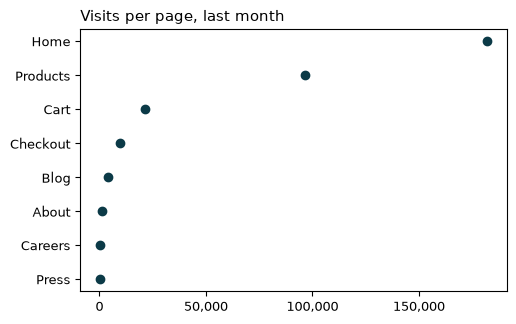

In [9]:
fig, ax = plt.subplots()
ax.scatter(pages['visits'], pages['page'])
ax.set_title('Visits per page, last month')
ax.invert_yaxis()
ax.set_xticks([0, 50000, 100000, 150000])
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.show()

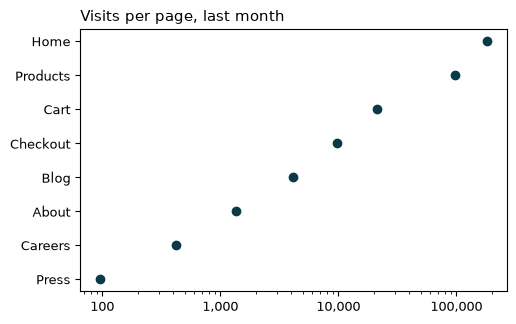

In [10]:
fig, ax = plt.subplots()
ax.scatter(pages['visits'], pages['page'])
ax.set_title('Visits per page, last month')
ax.invert_yaxis()
ax.set_xscale('log')
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.show()

### `ax.spines`

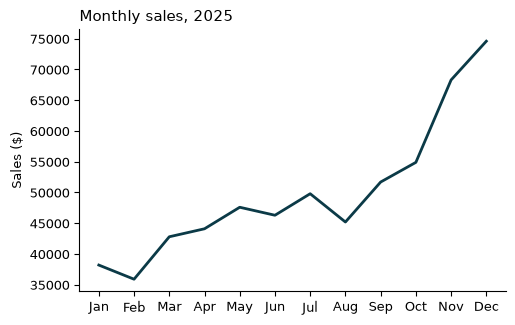

In [11]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.set_ylabel('Sales ($)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

### `ax.grid()`

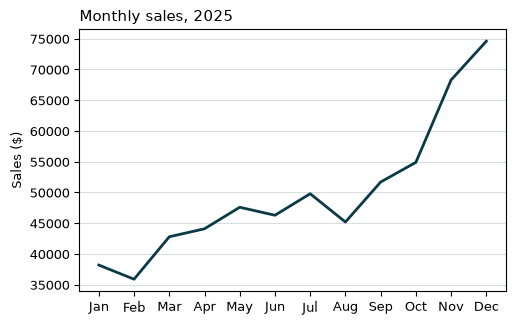

In [12]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.set_ylabel('Sales ($)')
ax.grid(axis='y')
plt.show()

## 7.3 Writing on the Chart

### `ax.text()`

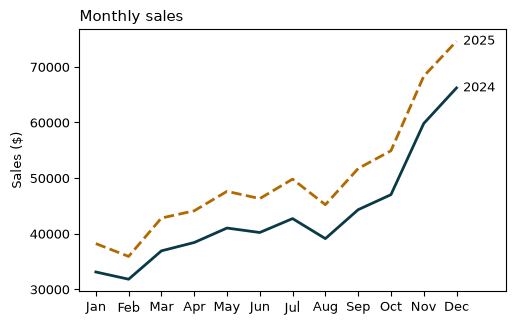

In [13]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2024'])
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales')
ax.set_ylabel('Sales ($)')
ax.set_xlim(-0.5, 12.5)
ax.text(11.2, 66200, '2024', va='center')
ax.text(11.2, 74600, '2025', va='center')
plt.show()

### `ax.annotate()`

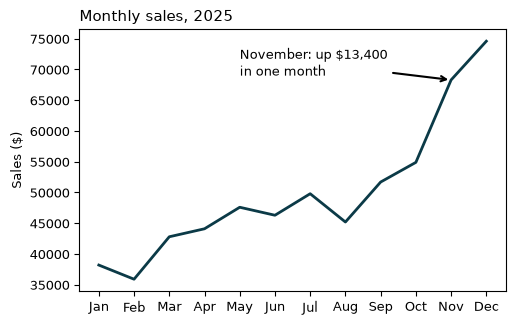

In [14]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.set_ylabel('Sales ($)')
ax.annotate('November: up $13,400\nin one month',
            xy=(10, 68300), xytext=(4, 69000),
            arrowprops={'arrowstyle': '->', 'lw': 1.5})
plt.show()

### `ax.axhline()` and `ax.axvline()`

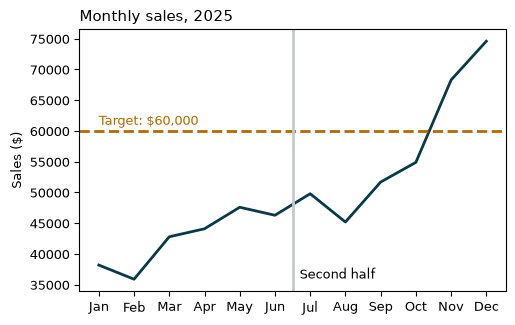

In [15]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.set_ylabel('Sales ($)')
ax.axhline(60000, color='#b26a00', linestyle='--')
ax.text(0, 61000, 'Target: $60,000', color='#b26a00')
ax.axvline(5.5, color='#c4c9ce')
ax.text(5.7, 36000, 'Second half')
plt.show()

### `ax.axvspan()`

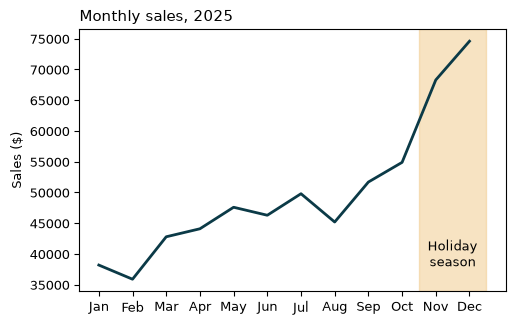

In [16]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
ax.set_ylabel('Sales ($)')
ax.axvspan(9.5, 11.5, color='#f0c987', alpha=0.5)
ax.text(10.5, 38000, 'Holiday\nseason', ha='center')
plt.show()

## 7.4 Colors and Colormaps

### Naming a color

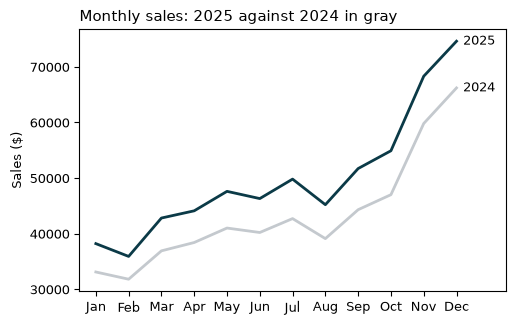

In [17]:
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2024'], color='#c4c9ce')
ax.plot(sales['month'], sales['sales_2025'], color='#0b3a47',
        linestyle='-')
ax.set_title('Monthly sales: 2025 against 2024 in gray')
ax.set_ylabel('Sales ($)')
ax.set_xlim(-0.5, 12.5)
ax.text(11.2, 66200, '2024', va='center')
ax.text(11.2, 74600, '2025', va='center')
plt.show()

### Colormaps

In [18]:
stores = pd.read_csv('store_stats.csv')
stores.head(3)

,store,visitors,daily_revenue,conversion
0,Seattle,310,2100,0.021
1,Oakland,180,1650,0.027
2,San Francisco,420,3300,0.024


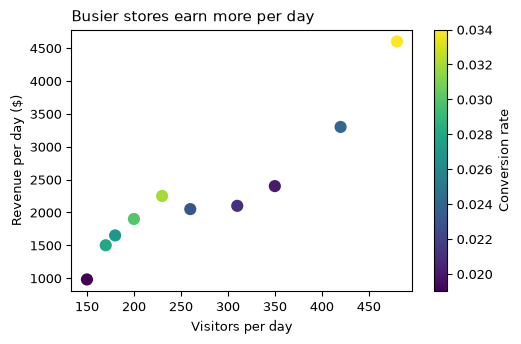

In [19]:
fig, ax = plt.subplots()
dots = ax.scatter(stores['visitors'], stores['daily_revenue'],
                  c=stores['conversion'], cmap='viridis', s=60)
fig.colorbar(dots, label='Conversion rate')
ax.set_title('Busier stores earn more per day')
ax.set_xlabel('Visitors per day')
ax.set_ylabel('Revenue per day ($)')
plt.show()

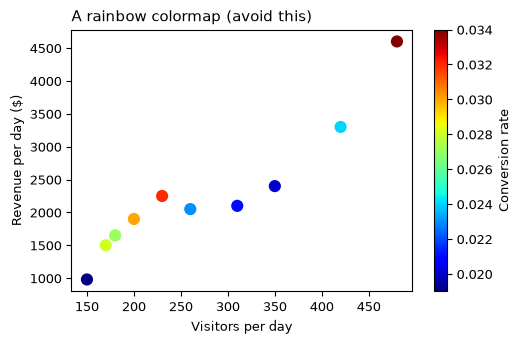

In [20]:
fig, ax = plt.subplots()
dots = ax.scatter(stores['visitors'], stores['daily_revenue'],
                  c=stores['conversion'], cmap='jet', s=60)
fig.colorbar(dots, label='Conversion rate')
ax.set_title('A rainbow colormap (avoid this)')
ax.set_xlabel('Visitors per day')
ax.set_ylabel('Revenue per day ($)')
plt.show()

## 7.5 Styles, rcParams and Fonts

### `plt.rcParams`

In [21]:
plt.rcParams['font.size']

9.5

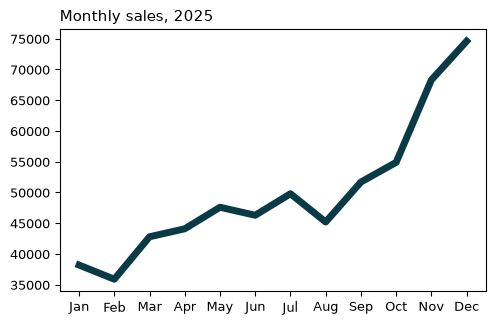

In [22]:
plt.rcParams['lines.linewidth'] = 5
fig, ax = plt.subplots()
ax.plot(sales['month'], sales['sales_2025'])
ax.set_title('Monthly sales, 2025')
plt.show()

In [23]:
plt.style.use('book.mplstyle')
plt.rcParams['lines.linewidth']

2.0

### `plt.rc_context()`

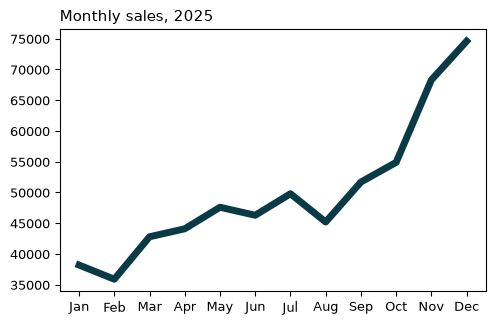

In [24]:
with plt.rc_context({'lines.linewidth': 5}):
    fig, ax = plt.subplots()
    ax.plot(sales['month'], sales['sales_2025'])
    ax.set_title('Monthly sales, 2025')
    plt.show()

### `plt.style.use()` with built-in styles

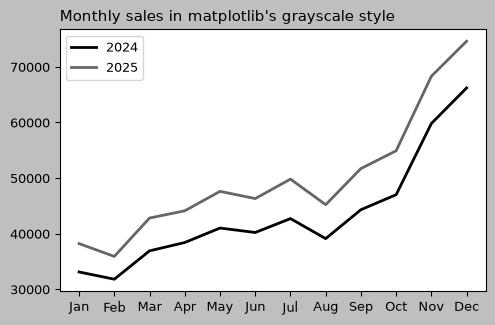

In [25]:
with plt.style.context('grayscale'):
    fig, ax = plt.subplots()
    ax.plot(sales['month'], sales['sales_2024'], label='2024')
    ax.plot(sales['month'], sales['sales_2025'], label='2025')
    ax.set_title('Monthly sales in matplotlib\'s grayscale style')
    ax.legend()
    plt.show()

Shown in the book but not run here:

```python
plt.style.use(['book.mplstyle', 'my_changes.mplstyle'])
```

### Fonts

In [26]:
plt.rcParams['font.family']

['sans-serif']

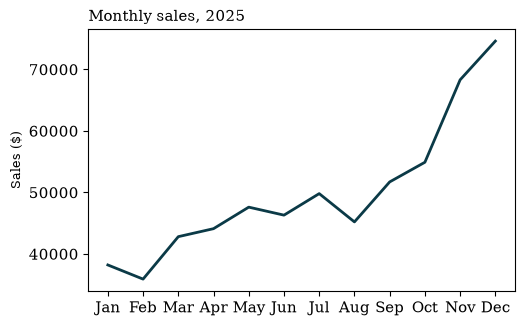

In [27]:
with plt.rc_context({'font.family': 'serif', 'font.size': 11}):
    fig, ax = plt.subplots()
    ax.plot(sales['month'], sales['sales_2025'])
    ax.set_title('Monthly sales, 2025')
    ax.set_ylabel('Sales ($)')
    plt.show()